# user

In [1]:
VERSION = "2.0.1_sextractor++"
RADIUS = 3.0
PIXEL_SCALE = 0.1

# lib

In [2]:
from pathlib import Path

from jax import numpy

from pandas import DataFrame, read_csv
from tqdm import tqdm
from utils import (
    image_fitting,
    slice_csv,
    histos,
    # weighted_ellips_model,
    residuals,
    # ellips_et,
    case_result_param,
    vignettes,
    # filter_matched,
    case_result,
    tfds_info,
    search_folder,
)


DATASET_DIR = Path("/net/GECO/pisco/PIX2SHEAR/DATASETS/pisco_euclid") / VERSION.replace("++", "")
RESULTS_DIR = Path("/net/GECO/pisco/PIX2SHEAR/RESULTS_SEXTRACTOR") / VERSION
CATALOG_DIR = RESULTS_DIR / "CATALOG"
IMAGES_DIR = RESULTS_DIR / "IMAGES"
PLOTS_DIR = RESULTS_DIR / "PLOTS"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# info databases

In [3]:
info = tfds_info(
    style="pisco_euclid",
    version=VERSION,
    data_dir=search_folder(name="DATASETS"),
)

for key, value in info.release_notes.items():
    print(f"{key}: {value}")

2.0.2: 2_000 (1000 + 1000 shape noise cancellation) 
2.1.2: 100_000 (50_000 + 50_000 shape noise cancellation)
2.1.1: 50_000
2.*.*: lhs + g round(2) + 10 gal/patch + g<|0.05| + e gauss + seeds 22 & 2222 + airy
2.0.1: 1_000


# inference

In [ ]:
from scipy.spatial import cKDTree


def filter_matched(query_df, tree_df, radius):
    tree = cKDTree(tree_df[["x", "y"]].values)
    distances, _ = tree.query(query_df[["x", "y"]].values, distance_upper_bound=radius)
    matched_mask = distances != numpy.inf
    return query_df[matched_mask].reset_index(drop=True)


def filter_unique_best_matches(query_df, tree_df, radius):
    """
    Match query points to tree points within a radius, ensuring each tree point is matched only once.
    If multiple queries try to match the same tree point, keep the one with the smallest distance.

    Returns:
        - matched_query_df
        - matched_tree_df
        - distances
    """
    tree = cKDTree(tree_df[["x", "y"]].values)
    query_points = query_df[["x", "y"]].values

    neighbors = tree.query_ball_point(query_points, r=radius)

    all_matches = []  # (query_idx, tree_idx, distance)

    for q_idx, nbrs in enumerate(neighbors):
        if len(nbrs) == 0:
            continue
        # Compute distances to all neighbors
        q_point = query_points[q_idx]
        tree_points = tree_df.iloc[nbrs][["x", "y"]].values
        dists = numpy.linalg.norm(tree_points - q_point, axis=1)

        for i, t_idx in enumerate(nbrs):
            all_matches.append((q_idx, t_idx, dists[i]))

    # Sort all matches by distance (smallest first)
    all_matches.sort(key=lambda x: x[2])

    # Enforce 1-to-1 mapping: track used query and tree indices
    used_queries = set()
    used_trees = set()
    final_matches = []

    for q_idx, t_idx, dist in all_matches:
        if q_idx not in used_queries and t_idx not in used_trees:
            used_queries.add(q_idx)
            used_trees.add(t_idx)
            final_matches.append((q_idx, t_idx, dist))

    # Extract matched rows
    matched_query_indices = [q for q, _, _ in final_matches]
    matched_tree_indices = [t for _, t, _ in final_matches]
    distances = [d for _, _, d in final_matches]

    matched_query_df = query_df.iloc[matched_query_indices].reset_index(drop=True)
    matched_tree_df = tree_df.iloc[matched_tree_indices].reset_index(drop=True)

    return matched_query_df, matched_tree_df  # , distances


def filter_best_single_match(query_df, tree_df, radius):
    tree = cKDTree(tree_df[["x", "y"]].values)
    query_points = query_df[["x", "y"]].values

    neighbors = tree.query_ball_point(query_points, r=radius)

    matched_query_indices = []
    matched_tree_indices = []
    distances = []

    for i, nbrs in enumerate(neighbors):
        if len(nbrs) == 0:
            continue  # No match within radius

        # Compute distances to all neighbors
        candidate_coords = tree_df.iloc[nbrs][["x", "y"]].values
        dists = numpy.linalg.norm(candidate_coords - query_points[i], axis=1)

        min_idx_in_nbrs = numpy.argmin(dists)
        best_tree_idx = nbrs[min_idx_in_nbrs]
        best_dist = dists[min_idx_in_nbrs]

        matched_query_indices.append(i)
        matched_tree_indices.append(best_tree_idx)
        distances.append(best_dist)

    matched_query_df = query_df.iloc[matched_query_indices].reset_index(drop=True)
    matched_tree_df = tree_df.iloc[matched_tree_indices].reset_index(drop=True)

    return matched_query_df, matched_tree_df, distances, matched_tree_indices


def filter_matched2(query_df, tree_df, radius):
    tree_true = cKDTree(tree_df[["x", "y"]].values)

    neighbors = tree_true.query_ball_point(query_df[["x", "y"]].values, r=radius)
    matched_mask = [len(n) > 0 for n in neighbors]
    return query_df[matched_mask].reset_index(drop=True)


def delete_duplicate(df_pred):
    duplicated_mask = df_pred["assoc1"].is_duplicated()

    df_duplicates = df_pred.filter(duplicated_mask)

    distance = (
        (df_duplicates["X_IMAGE"] - df_duplicates["assoc1"]) ** 2
        + (df_duplicates["Y_IMAGE"] - df_duplicates["assoc2"]) ** 2
    ).sqrt()

    df_duplicates = df_duplicates.with_columns(distance.alias("distance"))

    df_best = (
        df_duplicates.sort("distance").unique(subset=["assoc1"], keep="first").drop("distance")
    )

    df_pred = df_pred.filter(~duplicated_mask).vstack(df_best).sort("assoc1")

    return df_pred


In [4]:
def ellips_model(e1_err, e2_err, e1, e2):
    e1_err = e1_err.to_numpy()
    e2_err = e2_err.to_numpy()
    e1 = e1.to_numpy()
    e2 = e2.to_numpy()

    weight_e1 = 1 / numpy.sqrt(e1_err**2 + 0.26**2)
    e1_weighted_mean = numpy.sum(weight_e1 * e1) / numpy.sum(weight_e1)

    weight_e2 = 1 / numpy.sqrt(e2_err**2 + 0.26**2)
    e2_weighted_mean = numpy.sum(weight_e2 * e2) / numpy.sum(weight_e2)

    return float(e1_weighted_mean), float(e2_weighted_mean)


def ellips_se(e, theta):
    e = e.to_numpy()
    theta = theta.to_numpy()

    rad = numpy.deg2rad(theta)
    e1 = e * numpy.cos(2 * rad)
    e2 = e * numpy.sin(2 * rad)
    return float(e1.mean()), float(e2.mean())

In [5]:
PRED_FILES = sorted(list((CATALOG_DIR).glob("*_simu.csv")))
TRUE_FILES = sorted(list((DATASET_DIR).glob("*_true_galaxies_params.csv")))

all_obs_e1_model_err, all_obs_e2_model_err, all_obs_e1_model, all_obs_e2_model = [], [], [], []
all_obs_ell_se, all_obs_theta_se = [], []
avg_obs_e1_model, avg_obs_e2_model, avg_obs_e1_se, avg_obs_e2_se = [], [], [], []

mag, mag_err, sersic, sersic_err, hlr, hlr_err, true_mag, true_hlr, true_sersic = [
    [] for _ in range(9)
]
slice_sersic, slice_sersic_err, slice_mag, slice_mag_err, slice_hlr, slice_hlr_err = [
    [] for _ in range(6)
]
slice_true_hlr, slice_true_mag, slice_true_sersic = [[] for _ in range(3)]
detections = []

TOTAL = len(PRED_FILES)
for i, (result_file, true_file) in enumerate(tqdm(zip(PRED_FILES, TRUE_FILES), total=TOTAL)):
    df_pred = read_csv(result_file).sort_values(by="x", ascending=True)
    df_true = read_csv(true_file).sort_values(by="x", ascending=True)

    obs_e1_se, obs_e2_se = ellips_se(df_pred["ellipticity"], df_pred["ellipse_theta"])
    avg_obs_e1_se.append(obs_e1_se)
    avg_obs_e2_se.append(obs_e2_se)

    all_obs_ell_se.append(df_pred["ellipticity"].to_numpy())
    all_obs_theta_se.append(df_pred["ellipse_theta"].to_numpy())

    obs_e1_model, obs_e2_model = ellips_model(
        df_pred["e1_model_err"],
        df_pred["e2_model_err"],
        df_pred["e1_model_err"],
        df_pred["e2_model_err"],
    )
    avg_obs_e1_model.append(obs_e1_model)
    avg_obs_e2_model.append(obs_e2_model)

    all_obs_e1_model.append(df_pred["e1_model"].to_numpy())
    all_obs_e2_model.append(df_pred["e2_model"].to_numpy())
    all_obs_e1_model_err.append(df_pred["e1_model_err"].to_numpy())
    all_obs_e2_model_err.append(df_pred["e2_model_err"].to_numpy())

    mag.append(df_pred["mag_model"].to_numpy())
    mag_err.append(df_pred["mag_model_err"].to_numpy())
    # mag.append(df_pred["auto_mag"].to_numpy())
    # mag_err.append(df_pred["auto_mag_err"].to_numpy())

    sersic.append(df_pred["sersic_model"].to_numpy())
    sersic_err.append(df_pred["sersic_model_err"].to_numpy())

    hlr.append(df_pred["flux_model"].to_numpy())
    hlr_err.append(df_pred["flux_model_err"].to_numpy())
    # hlr.append(df_pred["flux_radius"].to_numpy())

    true_mag.append(df_true["mag"].to_numpy())
    true_sersic.append(df_true["sersic"].to_numpy())
    true_hlr.append(df_true["hlr"].to_numpy())

    NUMBER_DETECTED = df_pred.shape[0]
    detections.append(NUMBER_DETECTED)

    # if NUMBER_DETECTED != 10:
    #     # print(i)
    #     # print(df_pred.shape[0], df_true.shape[0])
    #     df_pred = df_pred[df_pred["assoc_match"]]
    #     # save_pred = df_pred
    #     # save_true = df_true
    #     # print(df_pred.shape[0], df_true.shape[0])

    #     df_pred, df_true = filter_unique_best_matches(df_pred, df_true, RADIUS)
    #     # if df_pred.shape[0] > df_true.shape[0]:
    #     #     df_pred = filter_matched(df_pred, df_true, radius=RADIUS)
    #     # else:
    #     #     df_true = filter_matched(df_true, df_pred, radius=RADIUS)

    #     # print(df_pred.shape[0], df_true.shape[0])
    #     assert df_pred.shape[0] == df_true.shape[0]

    slice_mag.append(df_pred["mag_model"].to_numpy())
    slice_mag_err.append(df_pred["mag_model_err"].to_numpy())
    # slice_mag.append(df_pred["auto_mag"].to_numpy())
    # slice_mag_err.append(df_pred["auto_mag_err"].to_numpy())

    slice_sersic.append(df_pred["sersic_model"].to_numpy())
    slice_sersic_err.append(df_pred["sersic_model_err"].to_numpy())

    slice_hlr.append(df_pred["flux_model"].to_numpy())
    slice_hlr_err.append(df_pred["flux_model_err"].to_numpy())
    # slice_hlr.append(df_pred["flux_radius"].to_numpy())

    slice_true_mag.append(df_true["mag"].to_numpy())
    slice_true_sersic.append(df_true["sersic"].to_numpy())
    slice_true_hlr.append(df_true["hlr"].to_numpy())

detections = numpy.array(detections)

sersic = numpy.concatenate(sersic)
sersic_err = numpy.concatenate(sersic_err)
true_sersic = numpy.concatenate(true_sersic)
slice_sersic = numpy.concatenate(slice_sersic)
slice_sersic_err = numpy.concatenate(slice_sersic_err)
slice_true_sersic = numpy.concatenate(slice_true_sersic)

mag = numpy.concatenate(mag)
mag_err = numpy.concatenate(mag_err)
true_mag = numpy.concatenate(true_mag)
slice_mag = numpy.concatenate(slice_mag)
slice_mag_err = numpy.concatenate(slice_mag_err)
slice_true_mag = numpy.concatenate(slice_true_mag)

hlr = numpy.concatenate(hlr)
hlr_err = numpy.concatenate(hlr_err)
true_hlr = numpy.concatenate(true_hlr)
slice_hlr = numpy.concatenate(slice_hlr)
slice_hlr_err = numpy.concatenate(slice_hlr_err)
slice_true_hlr = numpy.concatenate(slice_true_hlr)

loss_comp = round(((sersic.shape[0] - slice_sersic.shape[0]) / sersic.shape[0]) * 100, 2)
loss_gal = round(((sersic.shape[0]) / true_sersic.shape[0]) * 100, 2)

DataFrame(
    data={
        "avg_obs_e1_se": avg_obs_e1_se,
        "avg_obs_e2_se": avg_obs_e2_se,
        "avg_obs_e1_model": avg_obs_e1_model,
        "avg_obs_e2_model": avg_obs_e2_model,
    },
).to_csv(RESULTS_DIR / "pred_avg_obs_e.csv", index=False)


print("normal", sersic.shape[0], sersic_err.shape[0], true_sersic.shape[0])
print("slice", slice_sersic.shape[0], slice_sersic_err.shape[0], slice_true_sersic.shape[0])

del (
    df_pred,
    df_true,
    avg_obs_e1_model,
    avg_obs_e2_model,
    avg_obs_e1_se,
    avg_obs_e2_se,
    obs_e1_model,
    obs_e1_se,
    obs_e2_model,
    obs_e2_se,
)

100%|██████████| 1000/1000 [00:06<00:00, 145.30it/s]


normal 10098 10098 10000
slice 10098 10098 10000


# loading

In [ ]:
true_images_params = slice_csv(DATASET_DIR / "true_images_params.csv", TOTAL)

true_avg_obs_e = true_images_params[["avg_obs_e1", "avg_obs_e2"]].to_numpy()
true_avg_int_e = true_images_params[["avg_int_e1", "avg_int_e2"]].to_numpy()
true_avg_g = true_images_params[["avg_g1", "avg_g2"]].to_numpy()

pred_avg_obs_e = slice_csv(RESULTS_DIR / "pred_avg_obs_e.csv", TOTAL)
sex_pred_obs_e = pred_avg_obs_e[["avg_obs_e1_se", "avg_obs_e2_se"]].to_numpy()
model_pred_obs_e = pred_avg_obs_e[["avg_obs_e1_model", "avg_obs_e2_model"]].to_numpy()

print(true_avg_obs_e.shape, true_avg_int_e.shape, true_avg_g.shape, pred_avg_obs_e.shape)
del pred_avg_obs_e

(1000, 2) (1000, 2) (1000, 2) (1000, 4)


# histo

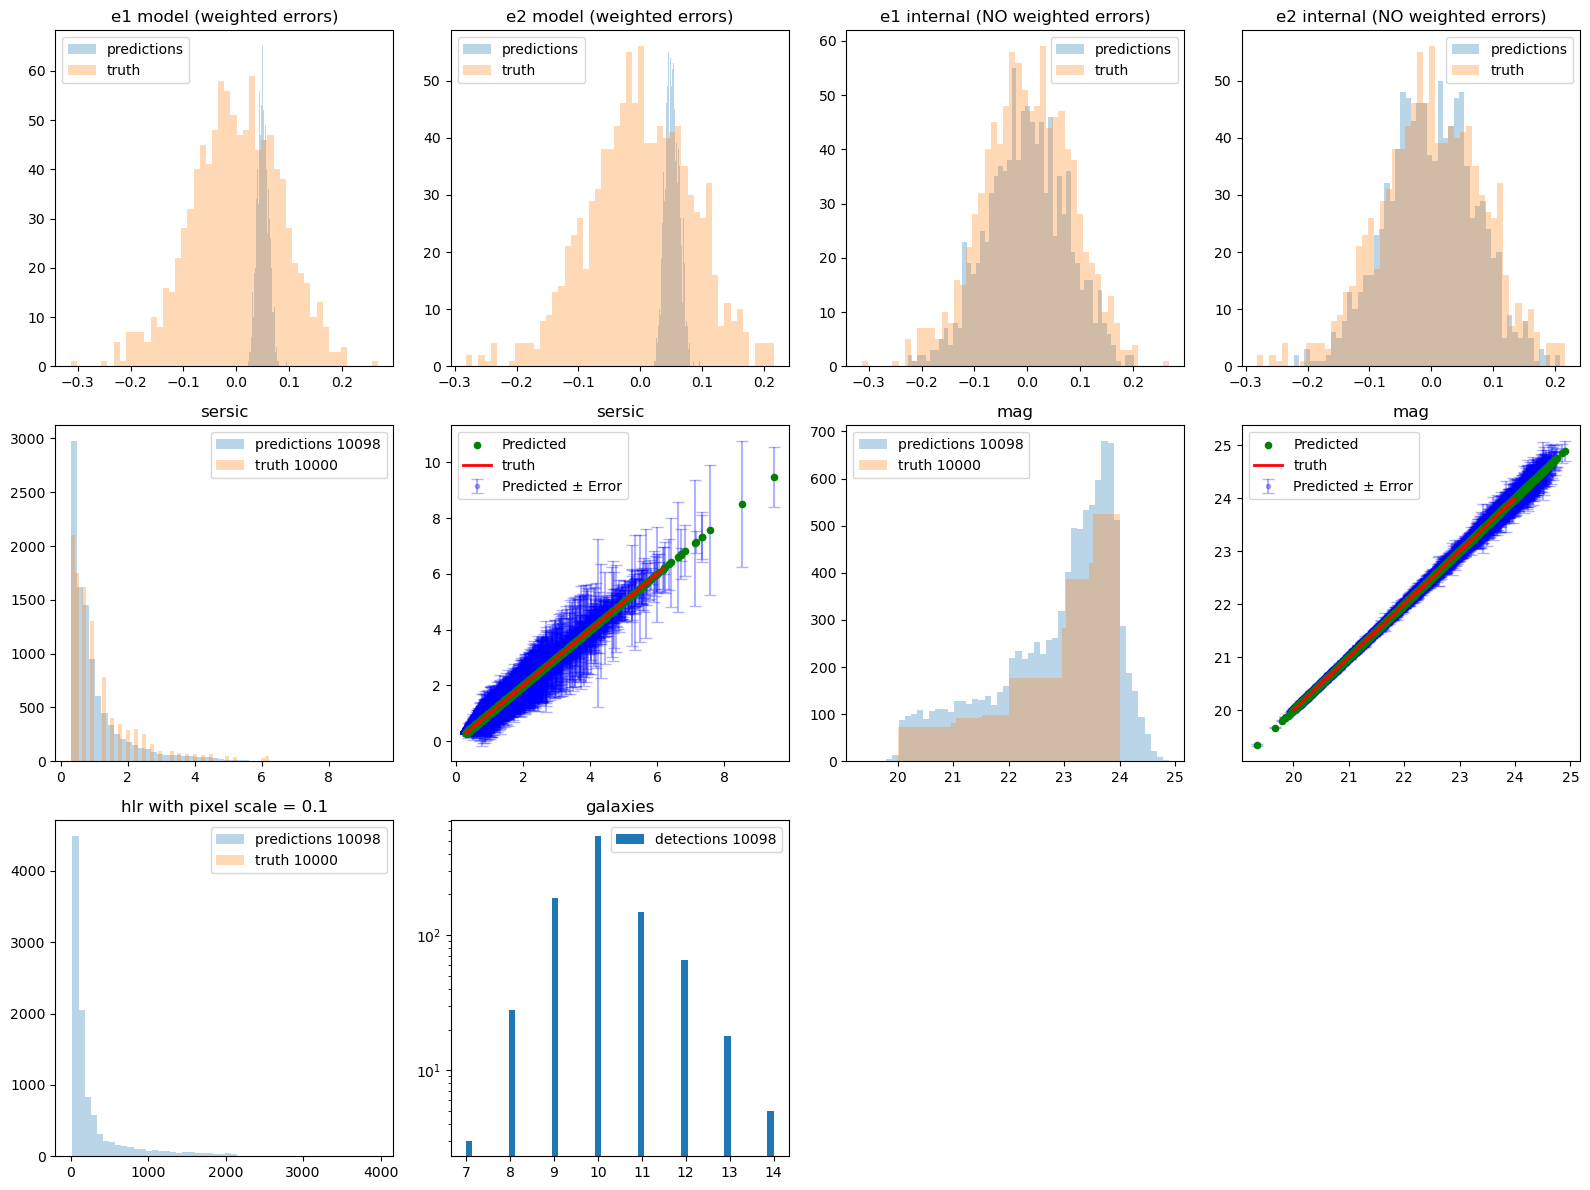

In [21]:
bins = 50
histos(
    detections,
    sersic,
    sersic_err,
    true_sersic,
    mag,
    mag_err,
    true_mag,
    hlr,
    true_hlr,
    sex_pred_obs_e,
    model_pred_obs_e,
    true_avg_obs_e,
    PLOTS_DIR,
    PIXEL_SCALE,
    bins=bins,
)

# results

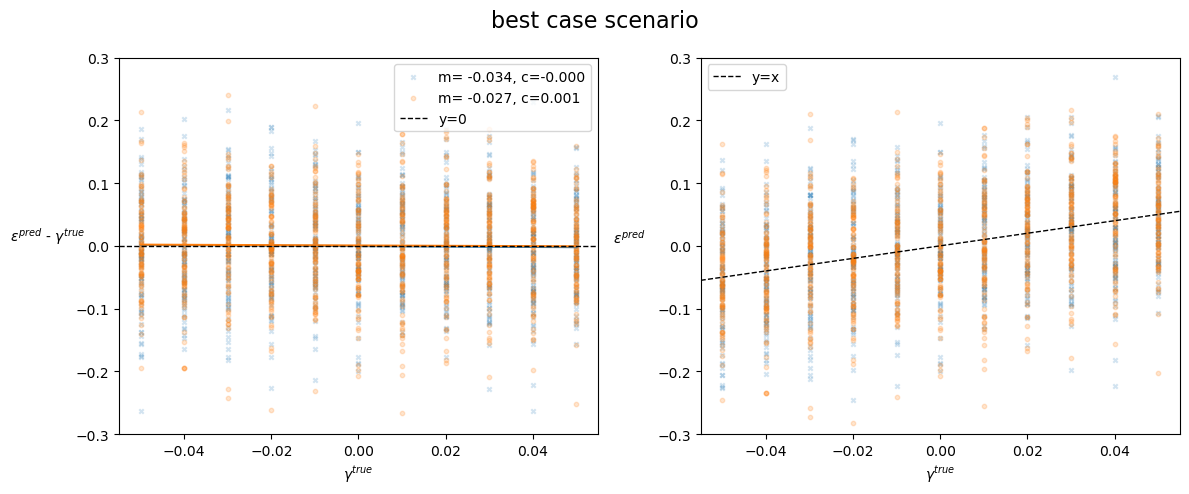

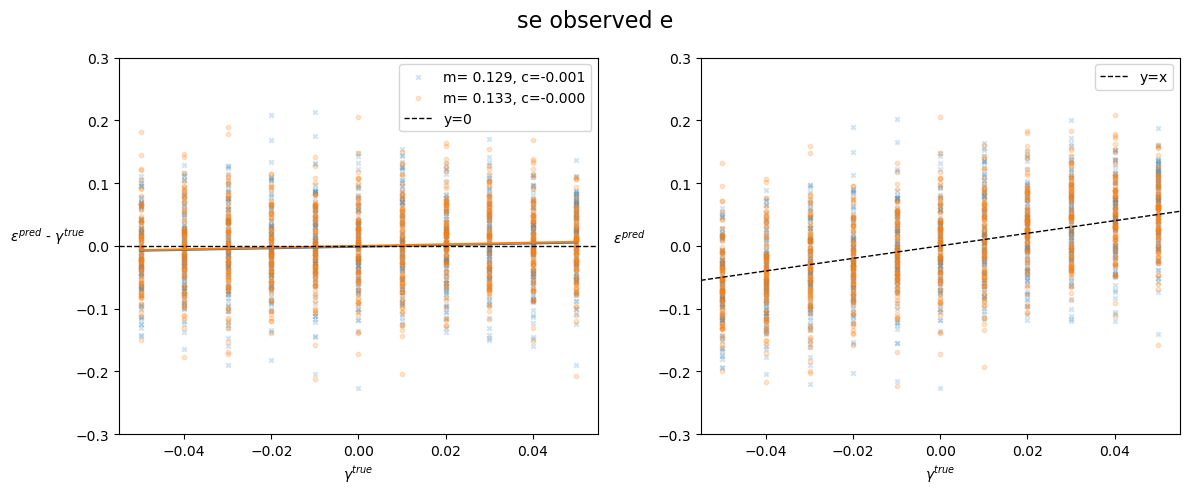

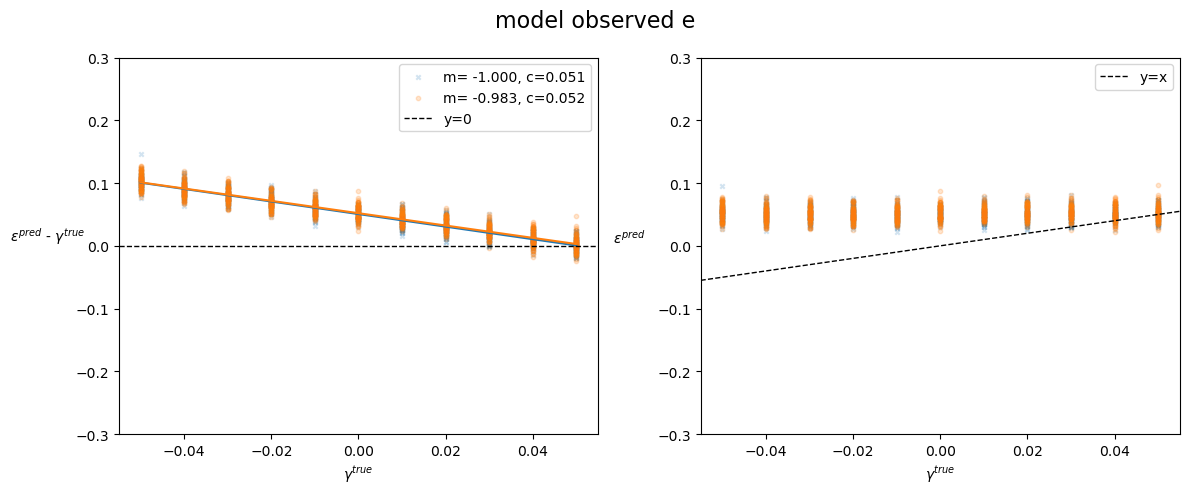

In [24]:
case_result(
    avg_obs_e=true_avg_obs_e,
    true_avg_g=true_avg_g,
    directory=PLOTS_DIR / "results_ell_best.pdf",
    title="best case scenario",
)
case_result(
    avg_obs_e=sex_pred_obs_e,
    true_avg_g=true_avg_g,
    directory=PLOTS_DIR / "results_ell_internal.pdf",
    title="se observed e",
)
case_result(
    avg_obs_e=model_pred_obs_e,
    true_avg_g=true_avg_g,
    directory=PLOTS_DIR / "results_ell_model.pdf",
    title="model observed e",
)

# results by params

In [25]:
case_result_param(
    slice_mag, slice_true_mag, loss_comp, loss_gal, PLOTS_DIR, err=slice_mag_err, symbol="mag"
)
case_result_param(
    slice_hlr, slice_true_hlr, loss_comp, loss_gal, PLOTS_DIR, symbol="hlr", pixel_scale=PIXEL_SCALE
)
case_result_param(slice_sersic, slice_true_sersic, loss_comp, loss_gal, PLOTS_DIR, symbol="sersic")

TypeError: sub got incompatible shapes for broadcasting: (10098,), (10000,).

# images

In [ ]:
CHOICE = "00003_simu"
image_fitting(DATASET_DIR, IMAGES_DIR, CHOICE, PLOTS_DIR)
image_fitting(DATASET_DIR, IMAGES_DIR, CHOICE, PLOTS_DIR, transformed=True)
residuals(DATASET_DIR, IMAGES_DIR, CHOICE, PLOTS_DIR)
vignettes(CATALOG_DIR, IMAGES_DIR, CHOICE, PLOTS_DIR)

# sersic

In [ ]:
# X_ser = FreeParameter(-2.3, Range((-10, 10), RangeType.LINEAR))
# add_prior(X_ser, -2.8, 1.1)
# MIN_SERSIC = 0.3
# MAX_SERSIC = 10
# sersic = DependentParameter(
#     lambda x: (MAX_SERSIC * numpy.exp(x) + MIN_SERSIC) / (1 + numpy.exp(x)), X_ser
# )

In [ ]:
# from matplotlib import pyplot


# MIN_SERSIC = 0.2
# MAX_SERSIC = 7


# def X_sersic(n):
#     return numpy.log((n - MIN_SERSIC) / (MAX_SERSIC - n))


# def orig_sersic(X):
#     return (MAX_SERSIC * numpy.exp(X) + MIN_SERSIC) / (1 + numpy.exp(X))


# def plot_sersic(X_min, X_max, X_sersic, orig_sersic, directory):
#     sersic_values = numpy.linspace(0.3, 10, 5000)
#     X_values = X_sersic(sersic_values)

#     X_inverse_values = numpy.linspace(X_min, X_max, 5000)
#     sersic_inverse_values = orig_sersic(X_inverse_values)

#     fig, ax1 = pyplot.subplots(figsize=(8, 5))

#     ax1.plot(sersic_values, X_values, label=r"$X_{\mathrm{sersic}}$", color="b")
#     ax1.axhline(X_min, color="r", linestyle="--", label="Prior lower bound")
#     ax1.axhline(X_max, color="g", linestyle="--", label="Prior upper bound")
#     ax1.fill_between(sersic_values, X_min, X_max, color="gray", alpha=0.2, label="Allowed range")

#     ax2 = ax1.twinx()
#     ax2.plot(
#         sersic_inverse_values, X_inverse_values, label="Inverse Mapping", color="orange", ls="--"
#     )
#     ax2.legend()

#     ax1.set_xlabel("Sersic Index (n)")
#     ax1.set_ylabel(r"$X_{\mathrm{sersic}}$")
#     ax1.set_title("Mapping of Sersic Index to X_sersic with Prior for numerical stability?")
#     ax1.legend()

#     ax1.grid(True)
#     fig.show()
#     fig.savefig(directory / "log_sersic.pdf", dpi=300)


# X_min, X_max = -7.5, 7.5
# plot_sersic(X_min, X_max, X_sersic, orig_sersic, PLOTS_DIR)
# del X_min, X_max

# compare

In [ ]:
# from numpy import array2string
# NB_TEST = 100

# RESULTS_FILES = sorted(list((CATALOG_DIR).glob("*_simu.csv")))
# for i, sample in enumerate(RESULTS_FILES):
#     if i == NB_TEST - 1:
#         df = read_csv(sample)
#         print(sample)
#         print(df["e1", "e2"].to_numpy())

#         true = read_csv(DATASET_DIR / f"{i + 1:05d}_true_galaxies_params.csv", skip_rows=0)
#         array = true["obs_e1", "obs_e2"].to_numpy()
#         print(DATASET_DIR / f"{i + 1:05d}_true_galaxies_params.csv")
#         print(array2string(array, formatter={"float_kind": lambda x: f"{x:.8e}"}))

#         # break